# Data loader test

In [ ]:
import os
import sys
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
import torch

sys.path.append(os.path.abspath(".."))

from loader.data_loader import get_data_loaders

## Load the data

In [2]:
train_loader, val_loader, test_loader, classes = get_data_loaders(num_workers=0)

print("Classes:", classes)
print("Train images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Test images:", len(test_loader.dataset))

Classes: ['1960s', '1970s', '1980s', '1990s', '2000s', '2010s']
Train images: 13986
Validation images: 2994
Test images: 3006


## Check that every decade has the same number of images

In [3]:
# count how many images of each decade are in every split
counts = {}
for name, loader in [("train", train_loader), ("validation", val_loader), ("test", test_loader)]:
    subset = loader.dataset
    labels = [subset.dataset.targets[i] for i in subset.indices]
    counter = Counter(labels)
    counts[name] = [counter[i] for i in range(len(classes))]

pd.DataFrame(counts, index=classes)

,train,validation,test
1960s,2331,499,501
1970s,2331,499,501
1980s,2331,499,501
1990s,2331,499,501
2000s,2331,499,501
2010s,2331,499,501


## Look at one batch

In [4]:
images, labels = next(iter(train_loader))

print("Images:", images.shape)  # (batch size, colour channels, height, width)
print("Labels:", labels.shape)

Images: torch.Size([32, 3, 128, 128])
Labels: torch.Size([32])


## Show some images

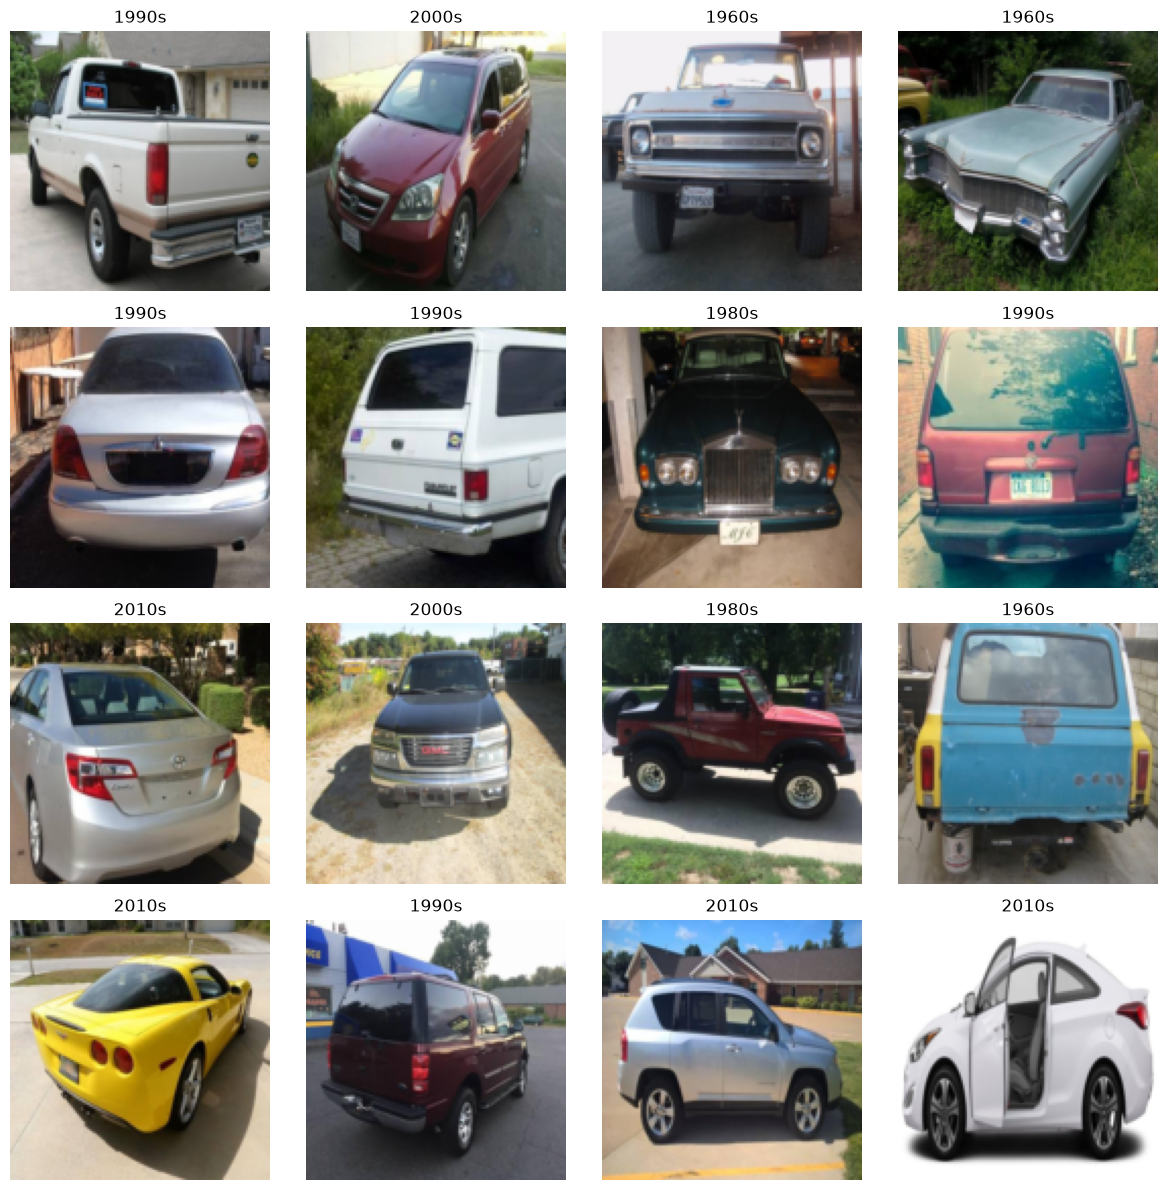

In [5]:
# same mean and std as in the data loader
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def to_image(image):
    image = image * std + mean      # undo the normalization
    image = image.permute(1, 2, 0)  # permute for matplotlib
    return image


# show the first 16 images of the batch with their decade
plt.figure(figsize=(12, 12))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(to_image(images[i]))
    plt.title(classes[labels[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

## A few images from every decade

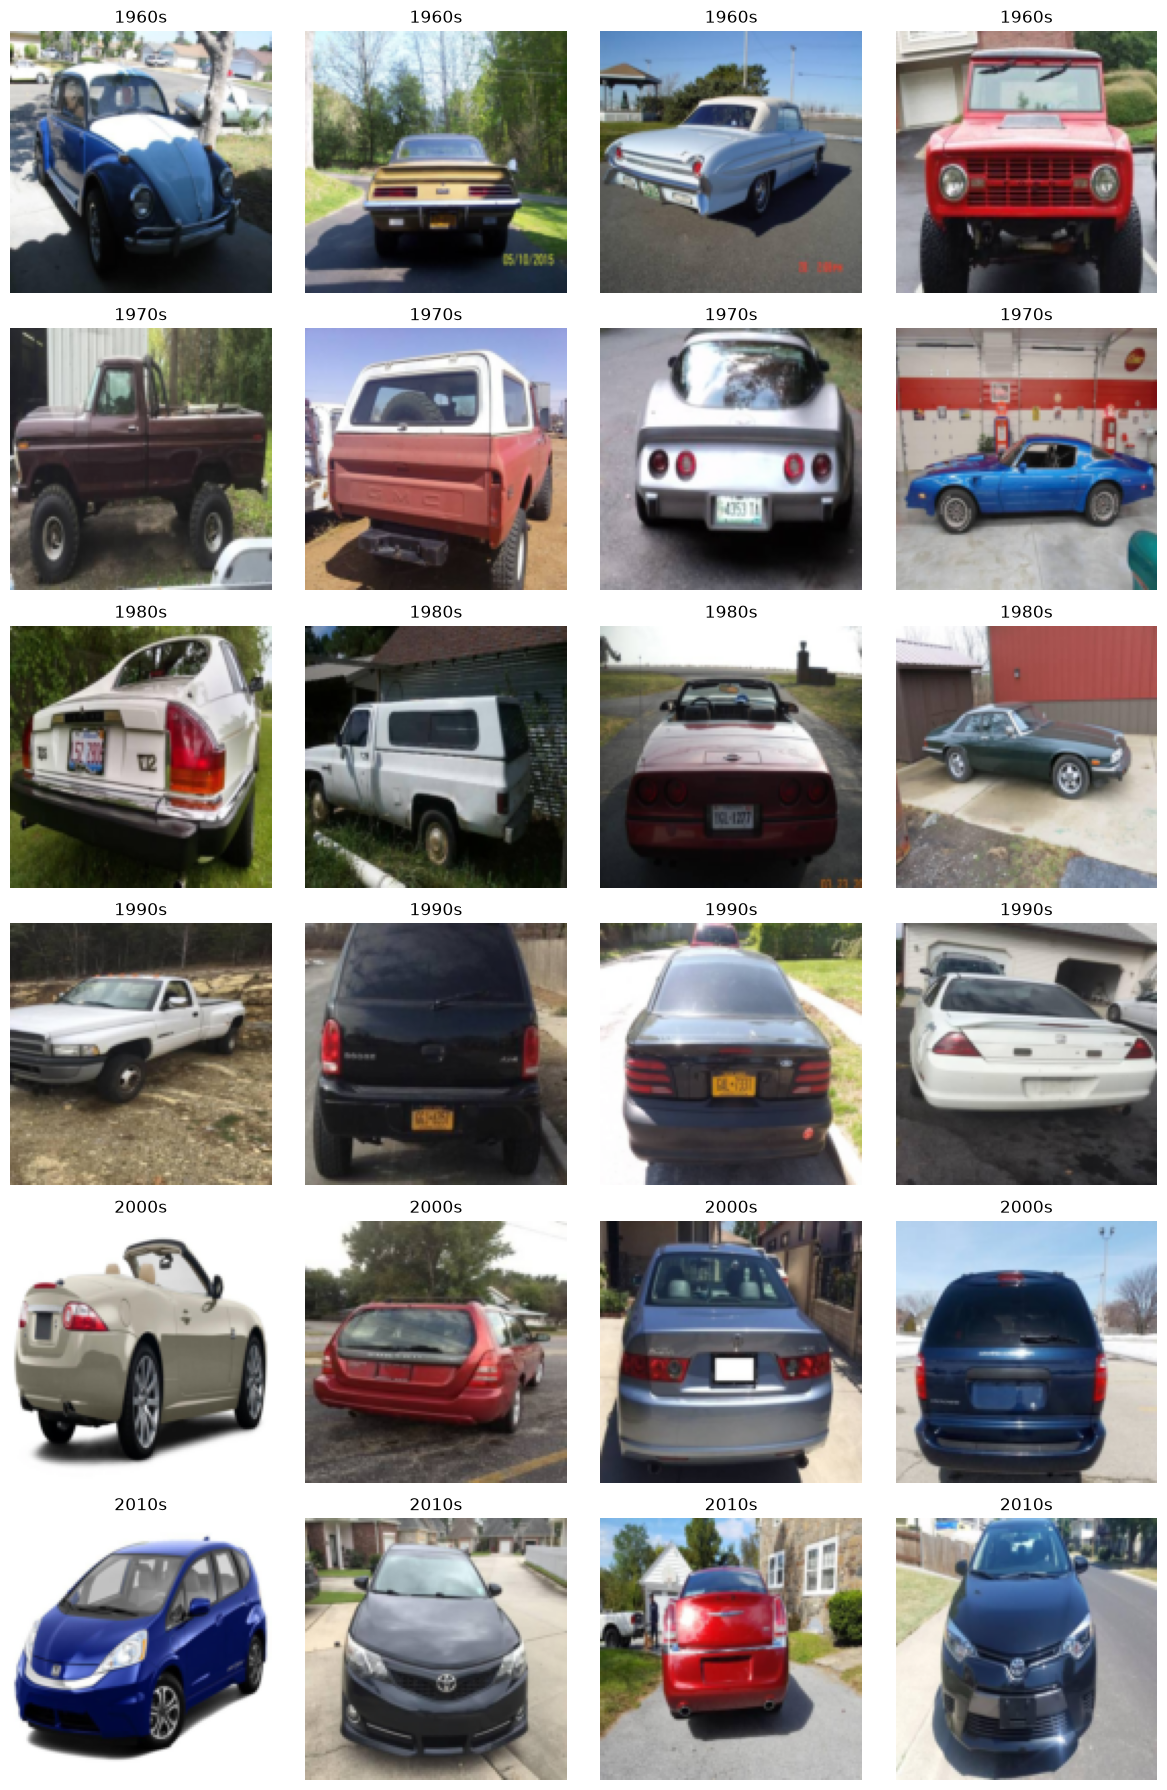

In [9]:
# show 4 training images of every decade, one row per decade
examples = 4
train_set = train_loader.dataset

plt.figure(figsize=(12, 18))
for row, decade in enumerate(classes):
    # positions of some images of this decade in the training set
    positions = []
    for i, index in enumerate(train_set.indices):
        if train_set.dataset.targets[index] == row: # append the index of this image if it has the right decade
            positions.append(i)
            if len(positions) == examples:
                break

    # show the images in this row
    for col in range(len(positions)):
        image, label = train_set[positions[col]]
        plt.subplot(len(classes), examples, row * examples + col + 1) # row * examples + col + 1 is the position in the grid
        plt.imshow(to_image(image))
        plt.title(decade)
        plt.axis("off")
plt.tight_layout()
plt.show()